# Exploratory Data Analysis on Engineered Features (32 Features — Merged 4-Class)

This notebook analyzes the statistical distributions, class separability, correlations, and mutual information of the **32 engineered URL features** (`Data/Features/merged_features.csv`):
1. **Setup & Paths:** Configure paths to `Data/Features/merged_features.csv` and `Reports/Images/`.
2. **Load Data + Feature Groups:** Group the 32 features into Lexical (20), Structural (7), and Statistical (5) categories.
3. **Class Distribution:** Inspect class proportions (`benign`: `394,154` · `phishing`: `116,196` · `defacement`: `76,246` · `malware`: `18,878`).
4. **Class Means Table:** Compare per-class feature means to verify directional signals (e.g., `domain_hyphens` enriched in `phishing` vs. `path_hyphens` enriched in `benign`).
5. **Boxplots by Feature Group (Merged):** Plot multi-class boxplots across Lexical, Structural, and Statistical feature groups (`Reports/Images/eda_features_merged_*_boxplot.png`).
6. **Boxplots Dataset 2:** Compare feature distributions specifically on the modern phishing subset.
7. **Correlation Heatmap + High-Correlation Pairs:** Identify collinear feature pairs (`|r| > 0.75`) using Pearson correlation (`Reports/Images/eda_features_merged_correlation.png`).
8. **Scatterplots for High-Correlation Pairs:** Visualize joint distributions of strongly correlated features across the 4 classes.
9. **Mutual Information Ranking:** Compute non-parametric Mutual Information scores with the 4-class target (`Reports/Images/eda_features_merged_mutual_info.png`).

## 1. Setup & Paths

In [9]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

BASE_DIR     = os.path.abspath(os.path.join(os.getcwd(), '..'))
FEATURES_DIR = os.path.join(BASE_DIR, 'Data', 'Features')
REPORTS_DIR  = os.path.join(BASE_DIR, 'Reports', 'images')
os.makedirs(REPORTS_DIR, exist_ok=True)

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

print(f"FEATURES_DIR : {FEATURES_DIR}")
print(f"REPORTS_DIR  : {REPORTS_DIR}")

FEATURES_DIR : d:\Study Assets\Final Project\PhishingGuard\Data\Features
REPORTS_DIR  : d:\Study Assets\Final Project\PhishingGuard\Reports\images


## 2. Load Data + Feature Groups

In [10]:
df = pd.read_csv(os.path.join(FEATURES_DIR, 'merged_features.csv'))

print("── Loaded ──")
print(f"  Merged : {df.shape} | Label: {sorted(df['Label'].unique())}")

FEATURE_GROUPS = {
    'Lexical': [
        'url_length', 'domain_length', 'path_length', 'num_dots',
        'domain_hyphens', 'path_hyphens',
        'num_underscores', 'num_slashes', 'num_at', 'num_question_marks',
        'num_equals', 'num_ampersands', 'num_percent', 'num_digits',
        'digit_ratio', 'letter_ratio', 'url_entropy', 'domain_entropy',
        'num_subdomains', 'has_ip_address'
    ],
    'Structural': [
        'is_suspicious_tld', 'has_port', 'path_depth',   # đã bỏ has_https
        'num_query_params', 'has_fragment', 'is_shortened_url', 'has_suspicious_word'
    ],
    'Statistical': [
        'consonant_ratio', 'vowel_ratio', 'longest_token_length',
        'avg_token_length', 'special_char_ratio'
    ]
}

ALL_FEATURES = sum(FEATURE_GROUPS.values(), [])
print(f"\nTotal features: {len(ALL_FEATURES)}")
for g, feats in FEATURE_GROUPS.items():
    print(f"  {g:12s}: {len(feats)} features")

── Loaded ──
  Merged : (605474, 34) | Label: ['benign', 'defacement', 'malware', 'phishing']

Total features: 32
  Lexical     : 20 features
  Structural  : 7 features
  Statistical : 5 features


## 3. Class Distribution

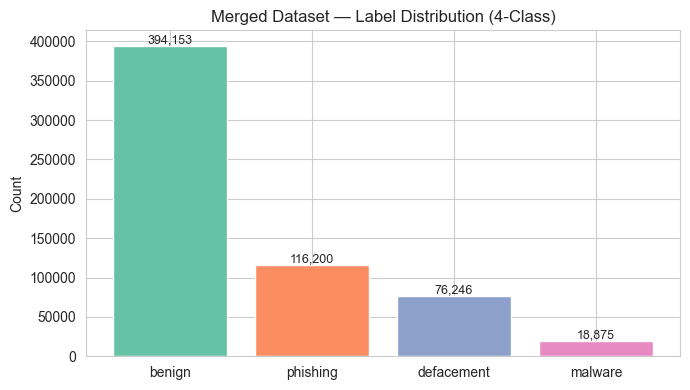


Merged: {'benign': np.int64(394153), 'phishing': np.int64(116200), 'defacement': np.int64(76246), 'malware': np.int64(18875)}


In [11]:
fig, ax = plt.subplots(figsize=(7, 4))

vc = df['Label'].value_counts()
ax.bar(vc.index, vc.values, color=sns.color_palette('Set2'))
ax.set_title('Merged Dataset — Label Distribution (4-Class)')
ax.set_ylabel('Count')
for i, v in enumerate(vc.values):
    ax.text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, 'eda_features_class_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f"\nMerged: {dict(vc)}")

## 4. Class Means Table

In [12]:
def class_means(df, label_col, features):
    return df.groupby(label_col)[features].mean().round(3)

print("── Merged Dataset: Mean feature values per class ──")
means = class_means(df, 'Label', ALL_FEATURES)
print(means.T.to_string())

── Merged Dataset: Mean feature values per class ──
Label                 benign  defacement  malware  phishing
url_length            67.061      83.282   46.587    55.066
domain_length         16.431      16.201   14.928    20.376
path_length           32.584      23.167   20.403    20.639
num_dots               1.931       2.142    3.022     2.145
domain_hyphens         0.109       0.216    0.147     0.318
path_hyphens           1.688       1.041    0.180     0.223
num_underscores        0.505       0.546    0.127     0.156
num_slashes            4.611       3.838    3.798     4.159
num_at                 0.001       0.000    0.001     0.010
num_question_marks     0.195       0.565    0.058     0.110
num_equals             0.395       2.299    0.170     0.254
num_ampersands         0.203       1.709    0.110     0.145
num_percent            0.669       0.039    0.667     0.066
num_digits             6.434       4.567   11.088     4.922
digit_ratio            0.069       0.045    0.26

## 5. Boxplots by Feature Group (Merged)

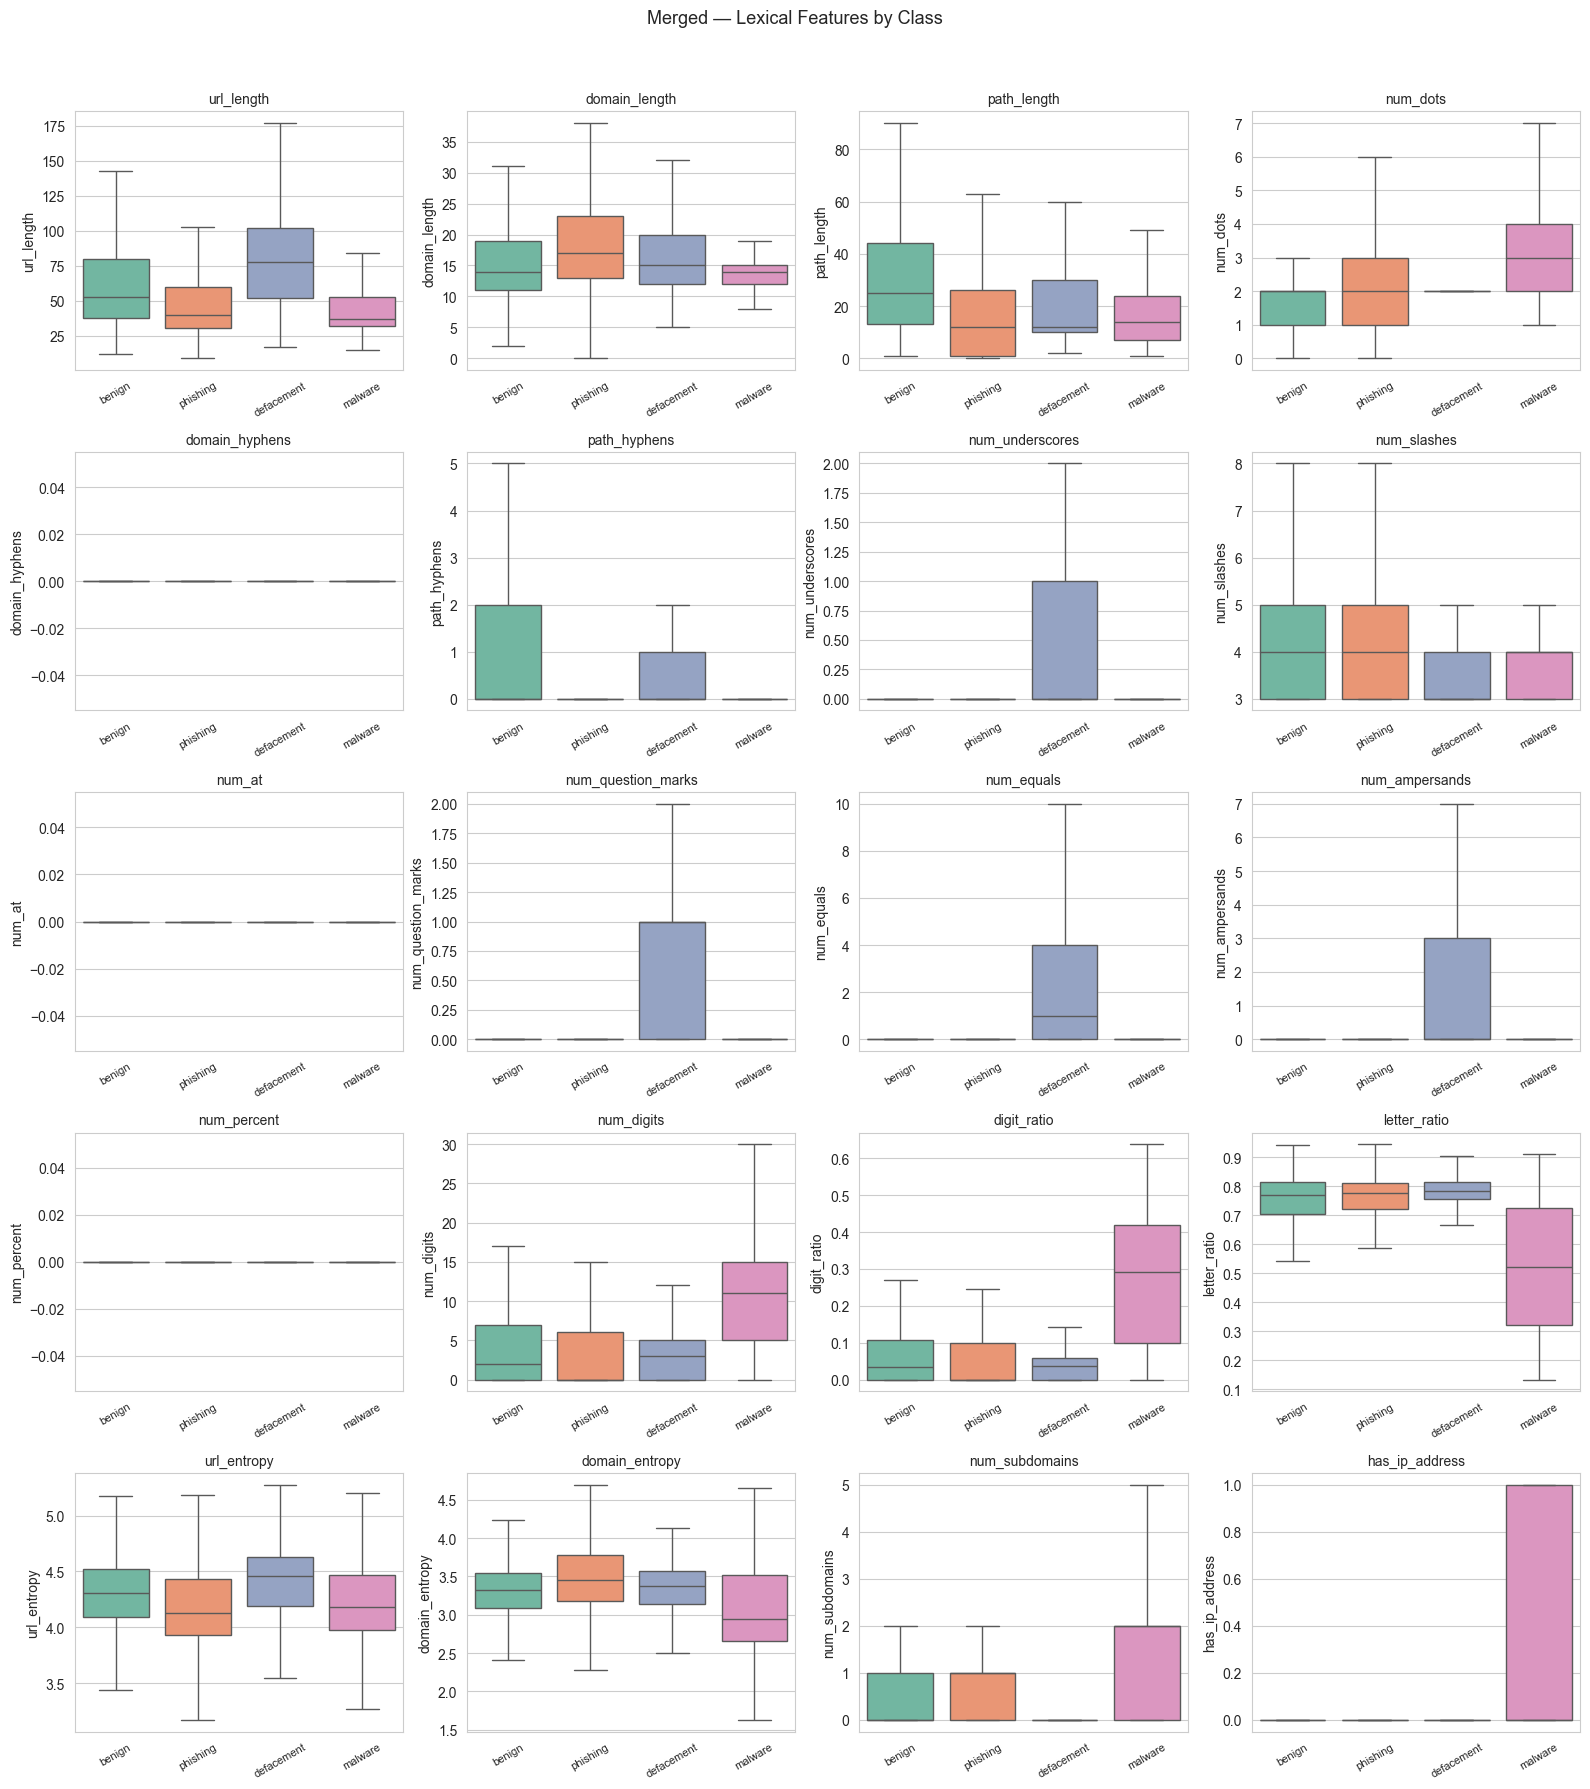

Saved → eda_features_merged_lexical_boxplot.png


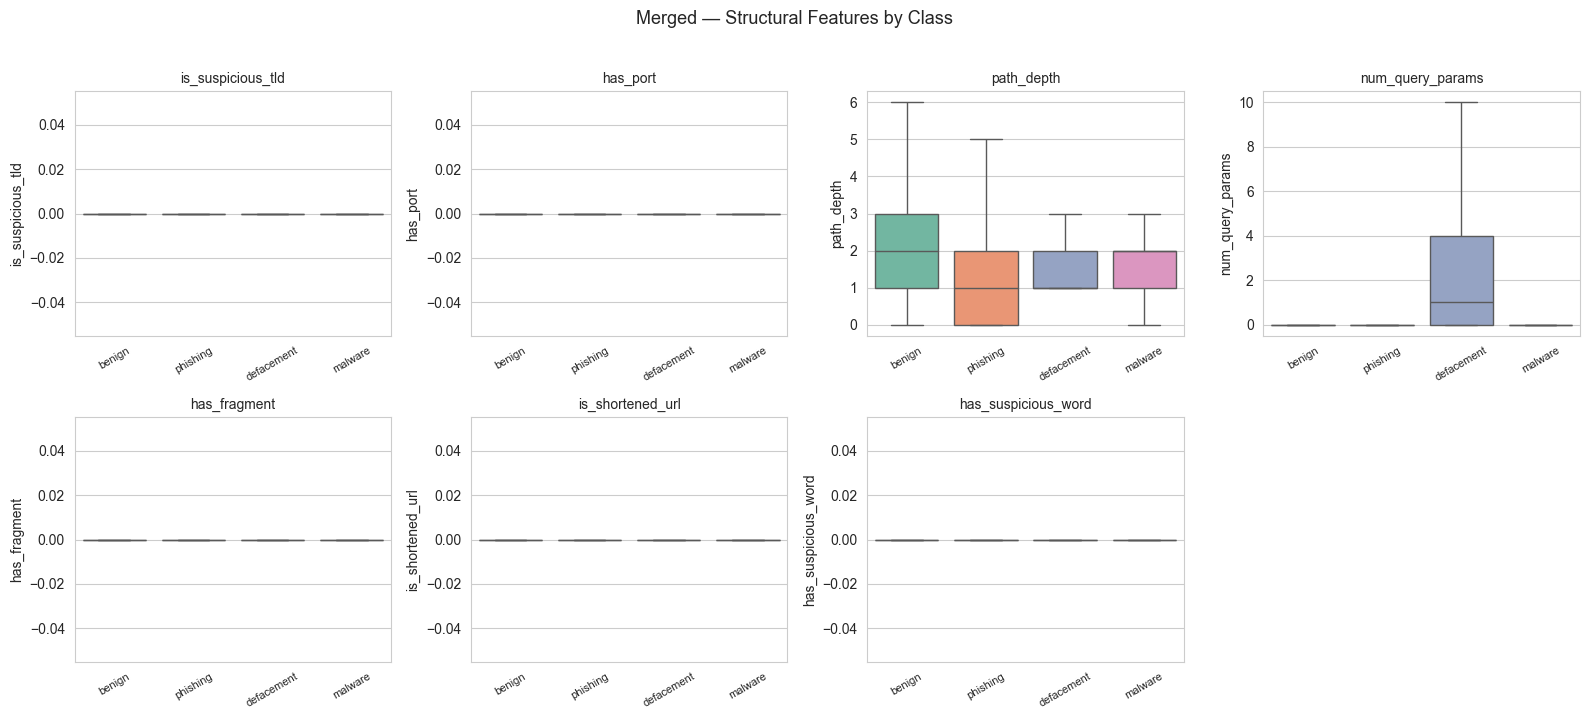

Saved → eda_features_merged_structural_boxplot.png


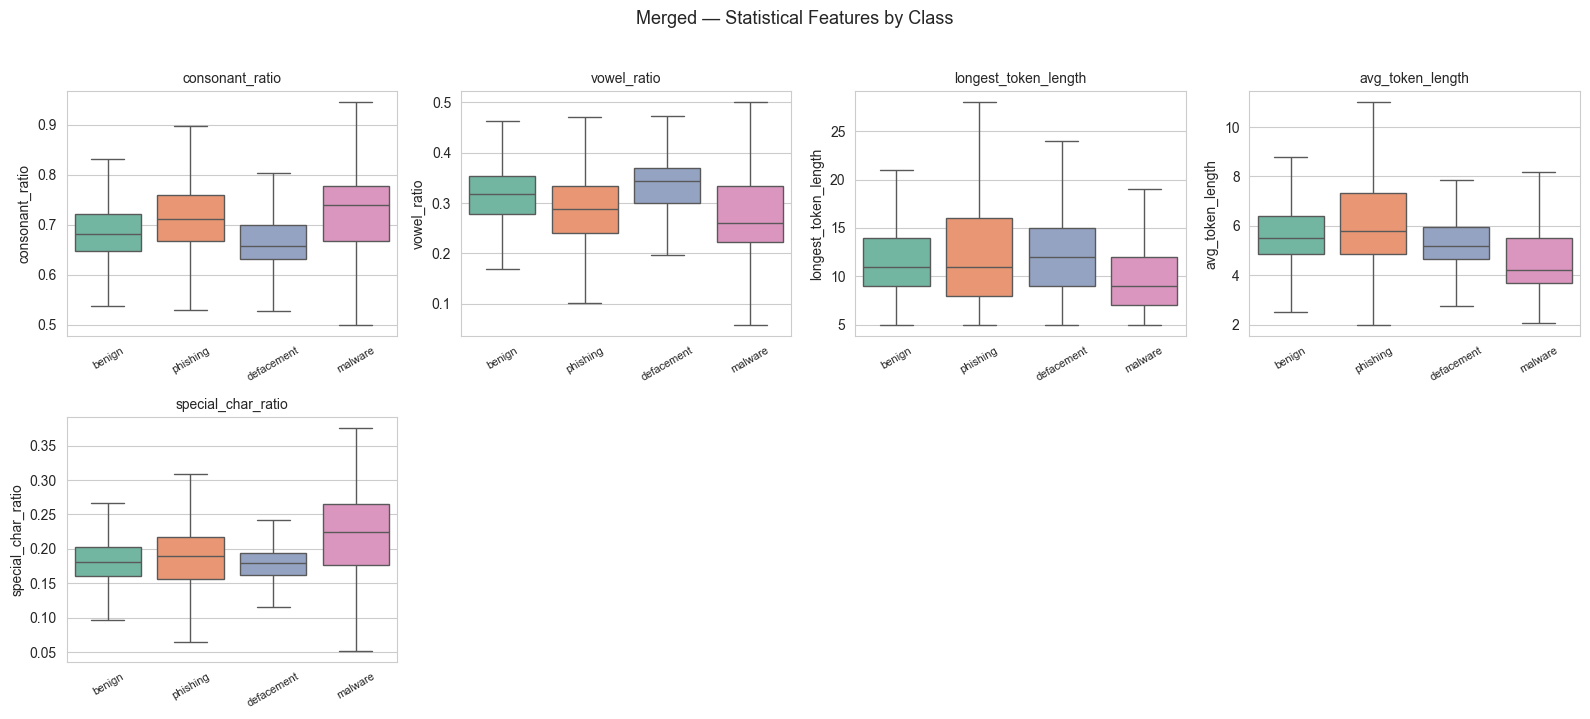

Saved → eda_features_merged_statistical_boxplot.png


In [13]:
def plot_group_boxplots(df, label_col, group_name, features, dataset_name, label_order=None):
    n = len(features)
    cols = 4
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols*4, rows*3.5))
    axes = axes.flatten()

    order = label_order if label_order else sorted(df[label_col].unique())

    for i, feat in enumerate(features):
        sns.boxplot(data=df, x=label_col, y=feat, ax=axes[i], order=order,
                    palette='Set2', showfliers=False)
        axes[i].set_title(feat, fontsize=10)
        axes[i].set_xlabel('')
        axes[i].tick_params(axis='x', rotation=30, labelsize=8)

    for j in range(n, len(axes)):
        axes[j].axis('off')

    fig.suptitle(f'{dataset_name} — {group_name} Features by Class', fontsize=13, y=1.02)
    plt.tight_layout()
    fname = f"eda_features_{dataset_name.lower().replace(' ', '')}_{group_name.lower()}_boxplot.png"
    plt.savefig(os.path.join(REPORTS_DIR, fname), dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved → {fname}")

label_order = ['benign', 'phishing', 'defacement', 'malware']

for group_name, feats in FEATURE_GROUPS.items():
    plot_group_boxplots(df, 'Label', group_name, feats, 'Merged', label_order)

## 6. Boxplots Dataset 2

## 7. Correlation Heatmap + High Correlation Pairs

── Merged Dataset ──


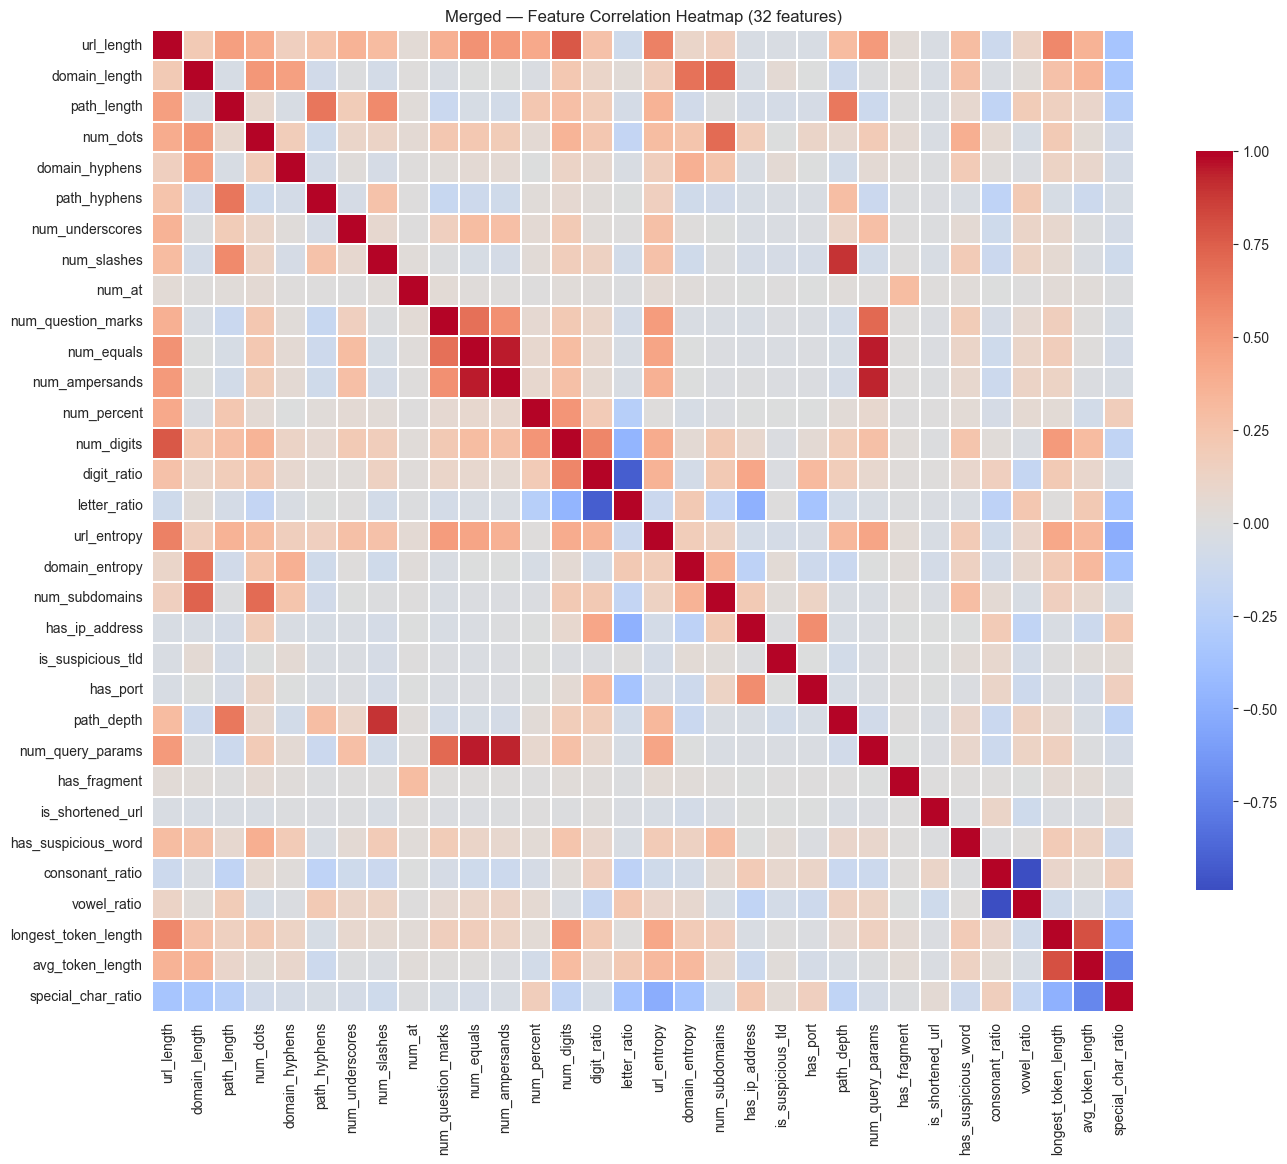

Saved → eda_features_merged_correlation.png

Highly correlated feature pairs (|corr| > 0.8):
      Feature 1        Feature 2  Correlation
     num_equals num_query_params     0.949553
     num_equals   num_ampersands     0.948506
 num_ampersands num_query_params     0.937708
    num_slashes       path_depth     0.893557
    digit_ratio     letter_ratio    -0.914964
consonant_ratio      vowel_ratio    -0.988458


In [14]:
def plot_correlation_heatmap(df, features, dataset_name):
    corr = df[features].corr()
    plt.figure(figsize=(14, 12))
    sns.heatmap(corr, cmap='coolwarm', center=0, annot=False,
                square=True, linewidths=0.3, cbar_kws={'shrink': 0.7})
    plt.title(f'{dataset_name} — Feature Correlation Heatmap ({len(features)} features)')
    plt.tight_layout()
    fname = f"eda_features_{dataset_name.lower().replace(' ', '')}_correlation.png"
    plt.savefig(os.path.join(REPORTS_DIR, fname), dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved → {fname}")

    high_corr = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    high_corr = high_corr.stack().reset_index()
    high_corr.columns = ['Feature 1', 'Feature 2', 'Correlation']
    high_corr = high_corr[high_corr['Correlation'].abs() > 0.8].sort_values('Correlation', ascending=False)

    print(f"\nHighly correlated feature pairs (|corr| > 0.8):")
    print(high_corr.to_string(index=False) if len(high_corr) > 0 else "  None")
    return high_corr

print("── Merged Dataset ──")
high_corr = plot_correlation_heatmap(df, ALL_FEATURES, 'Merged')

## 8. Scatterplots for High-Correlation Pairs

── Merged Dataset ──


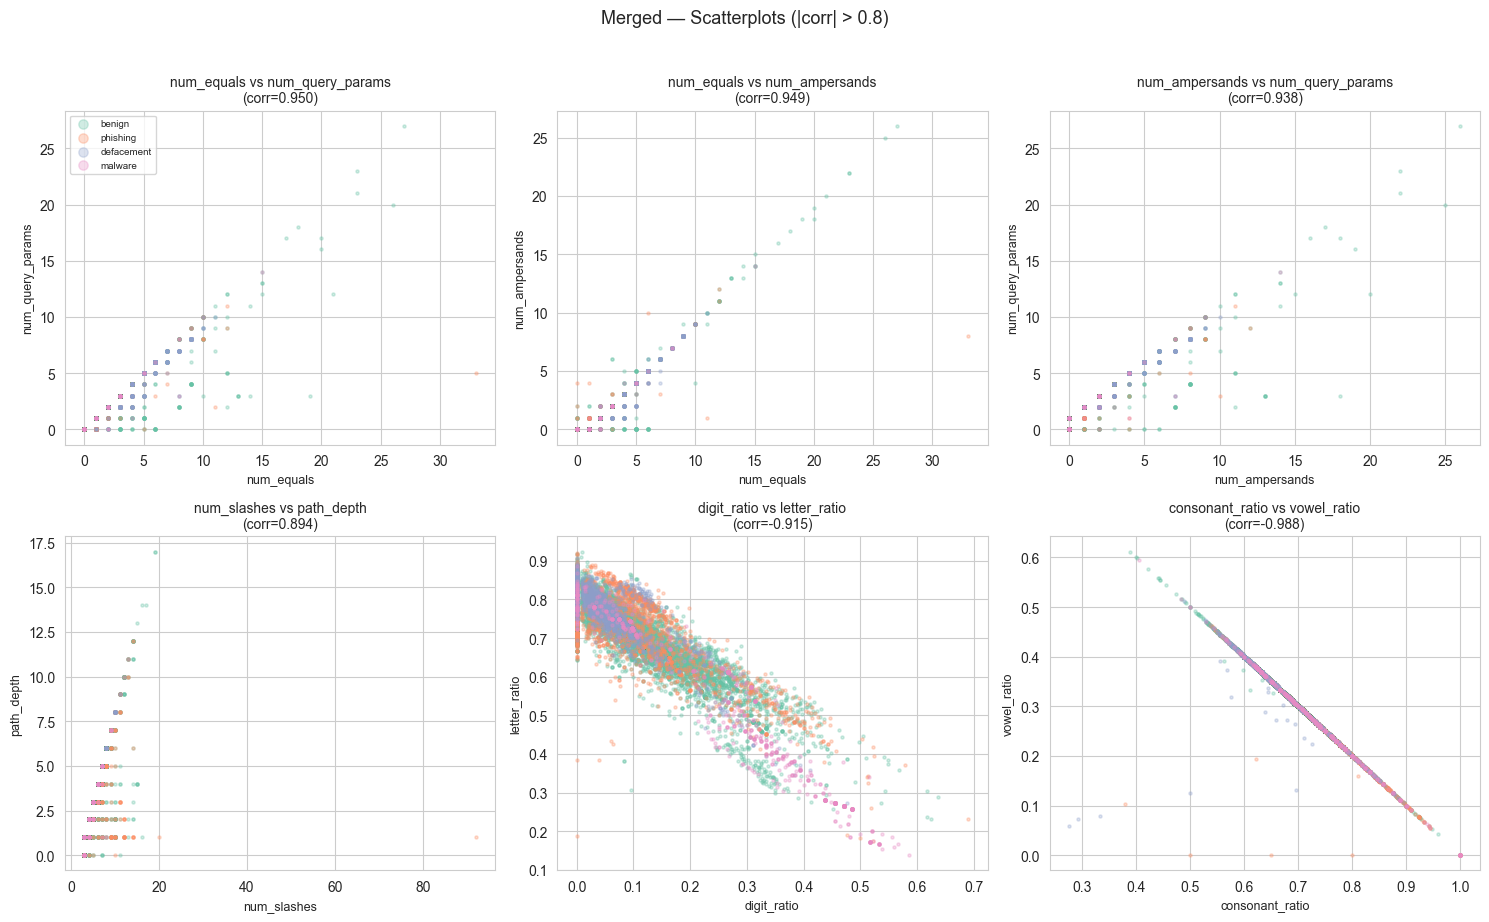

Saved → eda_features_merged_scatterplot.png


In [15]:
def plot_scatter_pairs(df, label_col, high_corr_df, dataset_name, label_order=None, sample_size=20000):
    if len(high_corr_df) == 0:
        print(f"[{dataset_name}] No feature pairs with |corr| > 0.8")
        return

    # Sample để vẽ nhanh hơn — scatterplot với 500K+ điểm sẽ rất chậm
    df_sample = df.sample(n=min(sample_size, len(df)), random_state=42)

    pairs = list(zip(high_corr_df['Feature 1'], high_corr_df['Feature 2']))
    n = len(pairs)
    cols = 3
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols*5, rows*4.5))
    axes = np.array(axes).flatten() if n > 1 else [axes]

    order = label_order if label_order else sorted(df[label_col].unique())
    palette = sns.color_palette('Set2', len(order))

    for i, (f1, f2) in enumerate(pairs):
        for j, label in enumerate(order):
            subset = df_sample[df_sample[label_col] == label]
            axes[i].scatter(subset[f1], subset[f2], s=5, alpha=0.3,
                           color=palette[j], label=label)
        corr_val = high_corr_df.iloc[i]['Correlation']
        axes[i].set_xlabel(f1, fontsize=9)
        axes[i].set_ylabel(f2, fontsize=9)
        axes[i].set_title(f'{f1} vs {f2}\n(corr={corr_val:.3f})', fontsize=10)
        if i == 0:
            axes[i].legend(fontsize=7, markerscale=3)

    for j in range(n, len(axes)):
        axes[j].axis('off')

    fig.suptitle(f'{dataset_name} — Scatterplots (|corr| > 0.8)', fontsize=13, y=1.02)
    plt.tight_layout()
    fname = f"eda_features_{dataset_name.lower().replace(' ', '')}_scatterplot.png"
    plt.savefig(os.path.join(REPORTS_DIR, fname), dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved → {fname}")

print("── Merged Dataset ──")
plot_scatter_pairs(df, 'Label', high_corr, 'Merged', label_order)

## 9. Mutual Information Ranking

── Merged: Top 15 features by Mutual Information ──
           Feature  Mutual Info
       path_length     0.176116
    domain_entropy     0.174031
       digit_ratio     0.150412
      letter_ratio     0.144435
special_char_ratio     0.138761
  avg_token_length     0.131532
       url_entropy     0.100981
  num_query_params     0.098606
       vowel_ratio     0.098489
   consonant_ratio     0.095818
        num_equals     0.089481
    num_ampersands     0.085865
        path_depth     0.078978
        url_length     0.075911
          num_dots     0.065511


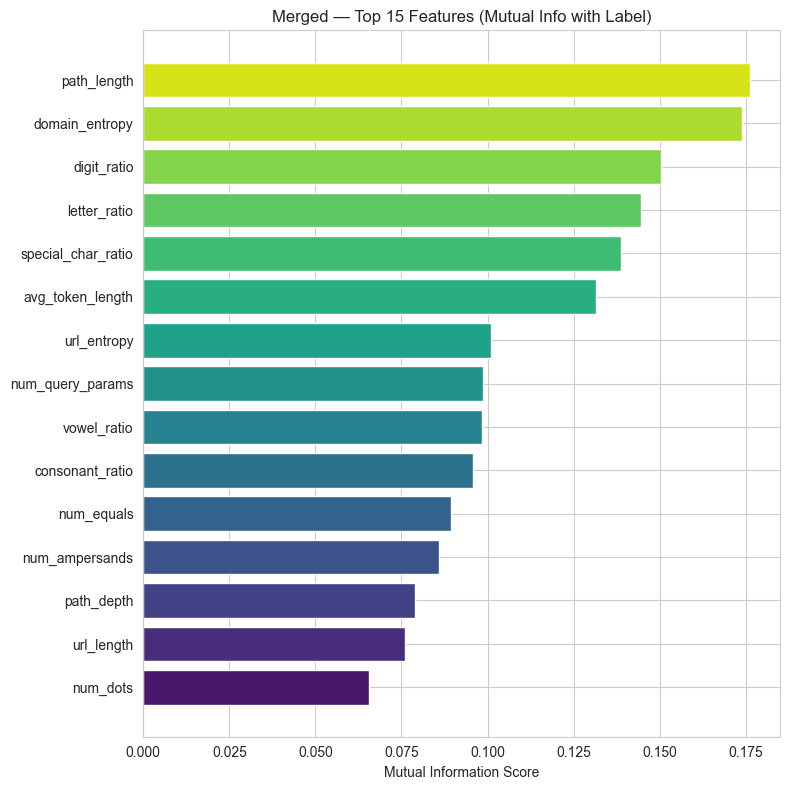

Saved → eda_features_merged_mutual_info.png


In [16]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder

def mutual_info_ranking(df, label_col, features, dataset_name, sample_size=50000):
    # Sample để tính nhanh hơn — MI ranking không cần full dataset
    df_sample = df.sample(n=min(sample_size, len(df)), random_state=42) if len(df) > sample_size else df

    X = df_sample[features].values
    if df_sample[label_col].dtype == object:
        le = LabelEncoder()
        y = le.fit_transform(df_sample[label_col])
    else:
        y = df_sample[label_col].values

    mi = mutual_info_classif(X, y, random_state=42, n_neighbors=3)
    mi_df = pd.DataFrame({'Feature': features, 'Mutual Info': mi})
    mi_df = mi_df.sort_values('Mutual Info', ascending=False).reset_index(drop=True)

    print(f"── {dataset_name}: Top 15 features by Mutual Information ──")
    print(mi_df.head(15).to_string(index=False))

    plt.figure(figsize=(8, 8))
    top15 = mi_df.head(15)
    plt.barh(top15['Feature'][::-1], top15['Mutual Info'][::-1],
             color=sns.color_palette('viridis', 15))
    plt.xlabel('Mutual Information Score')
    plt.title(f'{dataset_name} — Top 15 Features (Mutual Info with Label)')
    plt.tight_layout()
    fname = f"eda_features_{dataset_name.lower().replace(' ', '')}_mutual_info.png"
    plt.savefig(os.path.join(REPORTS_DIR, fname), dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved → {fname}")
    return mi_df

mi_merged = mutual_info_ranking(df, 'Label', ALL_FEATURES, 'Merged')